# A/B-тест формы оплаты ЖКХ



## 1. План эксперимента и определения метрик

Это реконструкция плана по завершённому кейсу и пример плана следующего теста.
В исходной выгрузке отсутствуют протокол запуска и заранее утверждённые параметры.

| Параметр | Решение для проекта |
|---|---|
| Продуктовая гипотеза | Автозаполнение увеличивает вероятность успешного завершения попытки оплаты |
| Период исходного теста | Открытия формы с 1 по 30 апреля 2024 года включительно |
| Распределение | По `user_id`, назначение берём из листа «Пользователи» |
| Основная метрика | Число успешных попыток / число открытий формы |
| H₀ и H₁ | H₀ — конверсии A и B равны. H₁ — различаются |
| Основная проверка | Двусторонний тест Вальда с клиентской оценкой дисперсии дельта-методом |
| Уровень значимости | 5% для основной гипотезы |
| Дополнительные метрики | Средняя клиентская конверсия, первая попытка, хотя бы одна оплата на клиента |
| План следующего теста | Мощность 80%, MDE +5 п.п., распределение 50/50. Эти параметры выбраны для учебного расчёта |
| Завершение следующего теста | Фиксированный горизонт, достаточная выборка, полный расчётный цикл и одинаковое время донаблюдения |
| Защитные метрики | Ошибки, повторные списания, возвраты, обращения в поддержку. Для них нужна отдельная выгрузка |

Главная метрика — отношение сумм. Клиенты с большим числом попыток получают больший вес.
Среднее индивидуальных конверсий отвечает на другой вопрос и даёт каждому клиенту одинаковый вес.

Анализ среди открывших форму предполагает, что правило попадания в этот срез одинаково
для A и B и открытие фиксируется до воздействия различий интерфейса. Отдельно посчитаем
долю с оплатой среди всех назначенных клиентов — проверку по принципу intention-to-treat (ITT).



In [1]:
from pathlib import Path
from hashlib import sha256
import json
import math
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scipy
import statsmodels
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportion_confint
from IPython.display import display, Markdown

ALPHA = 0.05
POWER = 0.80
MDE = 0.05
SEED = 42
TEST_START = pd.Timestamp('2024-04-01')
TEST_END = pd.Timestamp('2024-05-01')
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.figsize': (10, 4.5), 'figure.dpi': 110,
    'axes.titleweight': 'bold', 'axes.grid': True,
    'grid.alpha': 0.18, 'axes.axisbelow': True,
})
COLORS = {'A': '#496989', 'B': '#159A85'}

data_path = Path('data.xlsx')
if not data_path.exists():
    candidates = list(Path('.').glob('dannye-dlia-keisa*.xlsx'))
    if candidates:
        data_path = candidates[0]
    else:
        raise FileNotFoundError('Загрузи data.xlsx в ту же папку, где открыт notebook.')

users_raw = pd.read_excel(data_path, sheet_name='Пользователи')
payments_raw = pd.read_excel(data_path, sheet_name='Платежи')
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
print(f'Профили: {len(users_raw):,}. Попытки: {len(payments_raw):,}.')
display(users_raw.head())
display(payments_raw.head())

Профили: 1,504. Попытки: 2,661.


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,"1,001.0000",A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,"1,002.0000",A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,"1,003.0000",A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,"1,004.0000",A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,"1,004.0000",A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## 2. Проверка и очистка данных

Исходные таблицы сохраняем в переменных `users_raw` и `payments_raw`.
В рабочей копии проверяем идентификаторы, дубли, даты, порядок шагов и назначение групп.

| Ситуация | Правило обработки |
|---|---|
| Пустой или некорректный `user_id` попытки | Исключаем из анализа по клиентам и показываем количество |
| Пользователь отсутствует в реестре или группа неизвестна | Помещаем попытку в карантин |
| Полный повтор строки | Сохраняем одну копию. Конфликтующие записи с одинаковым ID требуют разбора |
| Несовпадение группы попытки и реестра | Основной анализ по назначению, дополнительный расчёт с исключением конфликта |
| Некорректная дата или порядок шагов | Помещаем попытку в карантин |
| Возраст вне 0–110 лет | Помечаем возраст как пропуск для демографического анализа |
| Пустой город | Выделяем категорию «Не указан» |
| Пропуск следующего шага | Считаем этот шаг незарегистрированным в доступной выгрузке |

Границы возраста выбраны как правило проверки качества для этого проекта.
Удаление профиля из-за возраста может изменить состав экспериментальных групп,
поэтому платёжные метрики сохраняют все валидные попытки.

In [2]:
users = users_raw.copy()
payments = payments_raw.drop_duplicates().copy()
full_duplicates = len(payments_raw) - len(payments)

users['group'] = users['group'].astype('string').str.strip().str.upper()
users['user_id'] = pd.to_numeric(users['user_id'], errors='coerce').astype('Int64')
if users['user_id'].isna().any() or users['user_id'].duplicated().any():
    raise ValueError('В реестре есть пустые или повторные user_id. Нужен разбор источника.')
if payments['payment_id'].isna().any() or payments['payment_id'].duplicated().any():
    raise ValueError('Есть пустые или конфликтующие payment_id. Нужен разбор источника.')

users['age_invalid'] = ~users['age'].between(0, 110)
users['age_clean'] = users['age'].where(~users['age_invalid'])
users['city_clean'] = users['city'].replace({
    'СПб': 'Санкт-Петербург', 'Регион': 'Другие регионы'
}).fillna('Не указан')
users['device_type'] = users['device_type'].astype('string').str.strip().str.lower()

numeric_ids = pd.to_numeric(payments['user_id'], errors='coerce')
invalid_id = numeric_ids.isna() | ~numeric_ids.mod(1).eq(0)
missing_ids = int(invalid_id.sum())
payments = payments.loc[~invalid_id].copy()
payments['user_id'] = numeric_ids.loc[~invalid_id].astype('Int64')
payments = payments.rename(columns={'group': 'group_payment'})
payments['group_payment'] = payments['group_payment'].astype('string').str.strip().str.upper()

invalid_date = pd.Series(False, index=payments.index)
for step in steps:
    parsed = pd.to_datetime(payments[step], errors='coerce')
    invalid_date |= payments[step].notna() & parsed.isna()
    payments[step] = parsed
payments['invalid_date'] = invalid_date

merged = payments.merge(users, on='user_id', how='left', validate='many_to_one', indicator=True)
unknown_user = merged['_merge'].ne('both')
unknown_group = ~merged['group'].isin(['A', 'B']) & ~unknown_user
outside_period = ~merged['step1_opened'].between(TEST_START, TEST_END, inclusive='left')
bad_sequence = pd.Series(False, index=merged.index)
for previous, following in zip(steps, steps[1:]):
    bad_sequence |= merged[following].notna() & (
        merged[previous].isna() | merged[following].lt(merged[previous])
    )

quarantine_mask = unknown_user | unknown_group | outside_period | bad_sequence | merged['invalid_date']
quarantine = merged.loc[quarantine_mask].copy()
events = merged.loc[~quarantine_mask].drop(columns='_merge').copy()
events['label_conflict'] = events['group_payment'].ne(events['group']).fillna(True)
events['success'] = events['step4_success'].notna().astype(int)
events['minutes_to_success'] = (
    events['step4_success'] - events['step1_opened']
).dt.total_seconds() / 60
events = events.sort_values(['step1_opened', 'payment_id']).reset_index(drop=True)

checks = pd.DataFrame({
    'Проверка': ['Исходные профили', 'Исходные попытки', 'Полные дубли попыток',
        'Попытки с некорректным user_id', 'Неизвестный клиент', 'Неизвестная группа',
        'Открытия вне периода', 'Нарушение порядка шагов', 'Некорректные даты',
        'Попытки в дополнительном карантине', 'Попытки в анализе', 'Конфликт метки группы',
        'Профили без назначения A/B', 'Аномальный возраст профиля', 'Пропуск города профиля'],
    'Количество': [len(users_raw), len(payments_raw), full_duplicates, missing_ids,
        int(unknown_user.sum()), int(unknown_group.sum()), int(outside_period.sum()),
        int(bad_sequence.sum()), int(merged['invalid_date'].sum()), len(quarantine), len(events),
        int(events['label_conflict'].sum()), int((~users['group'].isin(['A', 'B'])).sum()), int(users['age_invalid'].sum()),
        int(users_raw['city'].isna().sum())],
})
display(checks)
print('Причины дополнительного карантина могут пересекаться.')
display(events.loc[events['label_conflict'], ['payment_id', 'user_id', 'group', 'group_payment', 'success']])

Причины дополнительного карантина могут пересекаться.


,Проверка,Количество
0,Исходные профили,1504
1,Исходные попытки,2661
2,Полные дубли попыток,0
3,Попытки с некорректным user_id,1
4,Неизвестный клиент,0
5,Неизвестная группа,0
6,Открытия вне периода,0
7,Нарушение порядка шагов,0
8,Некорректные даты,0
9,Попытки в дополнительном карантине,0


,payment_id,user_id,group,group_payment,success
720,99002,1010,A,B,1


## 3. EDA на уровне клиентов

Сначала собираем попытки одного клиента. При повторном открытии формы клиент
сохраняет назначенную группу. Таблица `client` содержит одну строку на открывавшего форму,
таблица `assigned` — одну строку на назначенного клиента, включая клиентов без открытий.

Повторные попытки могут отражать обычное поведение. Их исключение изменило бы
определение основной метрики. Здесь проверяем распределение и сохраняем наблюдения.

Повторно открывали форму 761 клиентов из 1501.


,clients,opens,successes,mean_opens,median_opens,max_opens,repeat_clients,repeat_share,assigned_clients
group,,,,,,,,,
A,751,1309,652,1.7430,1.0000,4,364,0.4847,752
B,750,1351,870,1.8013,2.0000,4,397,0.5293,751


age_clean                                                         \
          count    mean    std     min     25%     50%     75%     max   
group                                                                    
A      751.0000 32.7400 7.8150 20.0000 27.0000 32.0000 38.0000 60.0000   
B      750.0000 32.6550 7.7750 20.0000 27.0000 33.0000 38.0000 60.0000   

         opens         ...                user_cr                              \
         count   mean  ...    75%    max    count   mean    std    min    25%   
group                  ...                                                      
A     751.0000 1.7430  ... 2.0000 4.0000 751.0000 0.5030 0.4210 0.0000 0.0000   
B     750.0000 1.8010  ... 2.0000 4.0000 750.0000 0.6550 0.3930 0.0000 0.3330   

                            
         50%    75%    max  
group                       
A     0.5000 1.0000 1.0000  
B     0.7500 1.0000 1.0000  

[2 rows x 24 columns]

,group,age,age_clean
1501,A,-5,NaN
1502,B,150,NaN


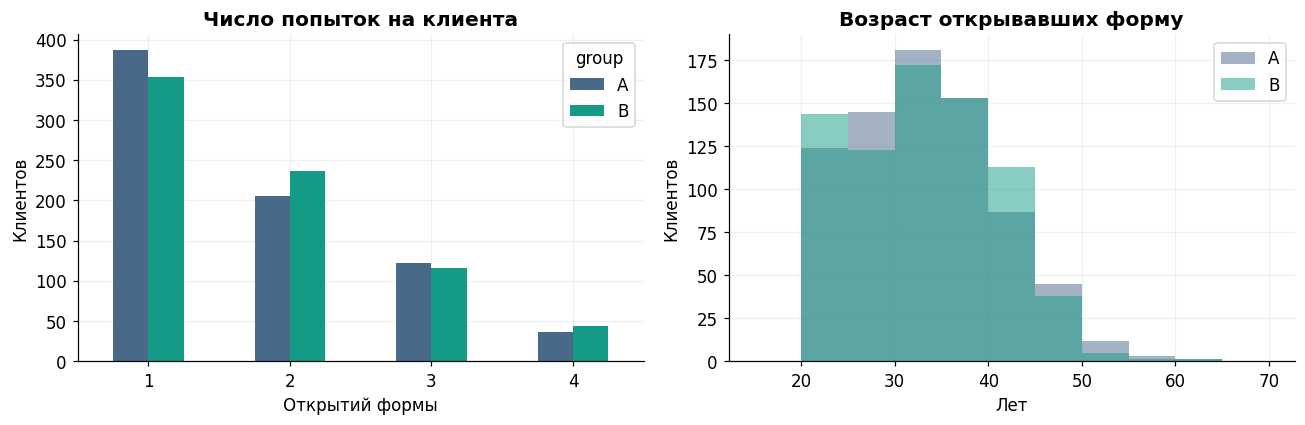

In [3]:
client = events.groupby(['user_id', 'group'], as_index=False).agg(
    opens=('payment_id', 'size'), successes=('success', 'sum'),
    first_success=('success', 'first'), first_open=('step1_opened', 'min'),
)
client['user_cr'] = client['successes'] / client['opens']
client['any_success'] = client['successes'].gt(0).astype(int)
client = client.merge(
    users[['user_id', 'device_type', 'city_clean', 'age_clean']], on='user_id', validate='one_to_one'
)
assigned = users.loc[users['group'].isin(['A', 'B'])].merge(
    client[['user_id', 'opens', 'successes', 'any_success']], on='user_id', how='left', validate='one_to_one'
)
assigned[['opens', 'successes', 'any_success']] = (
    assigned[['opens', 'successes', 'any_success']].fillna(0).astype(int)
)

eda = client.groupby('group').agg(
    clients=('user_id', 'size'), opens=('opens', 'sum'), successes=('successes', 'sum'),
    mean_opens=('opens', 'mean'), median_opens=('opens', 'median'), max_opens=('opens', 'max'),
)
eda['repeat_clients'] = client.loc[client['opens'].gt(1)].groupby('group').size()
eda['repeat_share'] = eda['repeat_clients'] / eda['clients']
eda['assigned_clients'] = assigned.groupby('group').size()
display(eda)
display(client.groupby('group')[['age_clean', 'opens', 'user_cr']].describe().round(3))
print(f"Повторно открывали форму {client['opens'].gt(1).sum()} клиентов из {len(client)}.")
display(users.loc[users['age_invalid'], ['group', 'age', 'age_clean']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = pd.crosstab(client['opens'], client['group']).reindex(columns=['A', 'B'], fill_value=0)
counts.plot.bar(ax=axes[0], color=[COLORS['A'], COLORS['B']], rot=0)
axes[0].set(title='Число попыток на клиента', xlabel='Открытий формы', ylabel='Клиентов')
for group in ['A', 'B']:
    axes[1].hist(client.loc[client['group'].eq(group), 'age_clean'].dropna(),
                 bins=np.arange(15, 71, 5), alpha=0.5, color=COLORS[group], label=group)
axes[1].set(title='Возраст открывавших форму', xlabel='Лет', ylabel='Клиентов')
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / '01_eda.png', bbox_inches='tight')
plt.show()

## 4. Проверка сплита и состава групп

SRM проверяет, соответствуют ли количества клиентов ожидаемому распределению 50/50.
Считаем его по назначениям и дополнительно по открывшим форму. Используем χ² с одной
степенью свободы. Большое p-value означает, что наблюдаемая разница количеств согласуется
с ожидаемым сплитом. О механизме рандомизации дополнительно судят по логам назначения.

Устройства и города сравниваем как доли внутри групп. Это описательная проверка состава.

In [4]:
srm_rows = []
for label, frame in [('Все назначения', assigned), ('Открывшие форму', client)]:
    observed = frame['group'].value_counts().reindex(['A', 'B']).to_numpy()
    result = stats.chisquare(observed, f_exp=np.repeat(observed.sum() / 2, 2))
    srm_rows.append({'Выборка': label, 'A': observed[0], 'B': observed[1],
                     'chi2': result.statistic, 'p_value': result.pvalue})
srm = pd.DataFrame(srm_rows)
display(srm)
for column in ['device_type', 'city_clean']:
    balance = pd.crosstab(client[column], client['group']).reindex(columns=['A', 'B'])
    balance['A_share_pct'] = 100 * balance['A'] / balance['A'].sum()
    balance['B_share_pct'] = 100 * balance['B'] / balance['B'].sum()
    balance['difference_pp'] = balance['B_share_pct'] - balance['A_share_pct']
    display(balance.round(2))

,Выборка,A,B,chi2,p_value
0,Все назначения,752,751,0.0007,0.9794
1,Открывшие форму,751,750,0.0007,0.9794


group,A,B,A_share_pct,B_share_pct,difference_pp
device_type,,,,,
android,407,369,54.1900,49.2000,-4.9900
ios,344,381,45.8100,50.8000,4.9900


group,A,B,A_share_pct,B_share_pct,difference_pp
city_clean,,,,,
Другие регионы,268,245,35.6900,32.6700,-3.0200
Москва,288,306,38.3500,40.8000,2.4500
Не указан,1,0,0.1300,0.0000,-0.1300
Санкт-Петербург,194,199,25.8300,26.5300,0.7000


## 5. Воронка и динамика

В таблице ниже доли каждого шага считаются от всех открытий формы своей группы.
Вторая таблица показывает переходы между соседними шагами.
Участники, дошедшие до промежуточного шага, могут различаться по составу между A и B,
поэтому условные конверсии описывают воронку, а причинный итог оцениваем по основной метрике.

Дневной график помогает увидеть качество данных и динамику. Остановка эксперимента
должна следовать заранее установленному горизонту и правилу принятия решения.

,Шаг,A_count,A_pct,B_count,B_pct
0,Открытие формы,1309,100.0000,1351,100.0000
1,Ввод реквизитов,1062,81.1300,1194,88.3800
2,Подтверждение,759,57.9800,960,71.0600
3,Успешная оплата,652,49.8100,870,64.4000


group,A,B,difference_pp
Открытие → реквизиты,81.1300,88.3800,7.2500
Реквизиты → подтверждение,71.4700,80.4000,8.9300
Подтверждение → оплата,85.9000,90.6200,4.7200


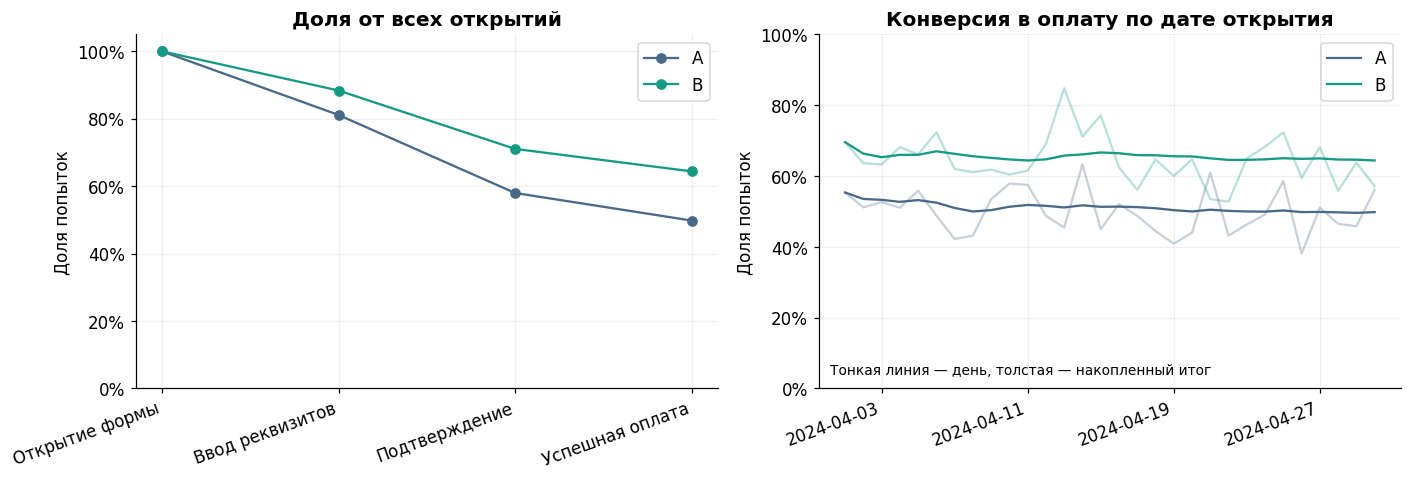

In [5]:
step_labels = ['Открытие формы', 'Ввод реквизитов', 'Подтверждение', 'Успешная оплата']
funnel_counts = events.groupby('group')[steps].count().reindex(['A', 'B'])
funnel_rates = funnel_counts.div(funnel_counts[steps[0]], axis=0)
funnel = pd.DataFrame({
    'Шаг': step_labels,
    'A_count': funnel_counts.loc['A'].to_numpy(),
    'A_pct': 100 * funnel_rates.loc['A'].to_numpy(),
    'B_count': funnel_counts.loc['B'].to_numpy(),
    'B_pct': 100 * funnel_rates.loc['B'].to_numpy(),
})
display(funnel.round(2))
conditional = funnel_counts.div(funnel_counts.shift(1, axis=1)).iloc[:, 1:].T
conditional.index = ['Открытие → реквизиты', 'Реквизиты → подтверждение', 'Подтверждение → оплата']
conditional *= 100
conditional['difference_pp'] = conditional['B'] - conditional['A']
display(conditional.round(2))

daily = events.assign(day=events['step1_opened'].dt.normalize()).groupby(['day', 'group']).agg(
    opens=('success', 'size'), successes=('success', 'sum')
)
daily['cr'] = daily['successes'] / daily['opens']
daily['cumulative_cr'] = daily.groupby('group')['successes'].cumsum() / daily.groupby('group')['opens'].cumsum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for group in ['A', 'B']:
    axes[0].plot(step_labels, funnel_rates.loc[group], marker='o', color=COLORS[group], label=group)
    group_daily = daily.xs(group, level='group')
    axes[1].plot(group_daily.index, group_daily['cr'], color=COLORS[group], alpha=0.3)
    axes[1].plot(group_daily.index, group_daily['cumulative_cr'], color=COLORS[group], label=group)
axes[0].set(title='Доля от всех открытий', ylabel='Доля попыток', ylim=(0, 1.05))
axes[0].tick_params(axis='x', labelrotation=12)
axes[1].set(title='Конверсия в оплату по дате открытия', ylabel='Доля попыток', ylim=(0, 1))
axes[1].text(0.02, 0.04, 'Тонкая линия — день, толстая — накопленный итог', transform=axes[1].transAxes, fontsize=9)
axes[1].xaxis.set_major_locator(plt.MaxNLocator(5))
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.legend()
fig.autofmt_xdate(rotation=20)
fig.tight_layout()
fig.savefig(OUT / '02_funnel_daily.png', bbox_inches='tight')
plt.show()

## 6. Основная проверка с учётом клиента

Дельта-метод сохраняет определение общей конверсии и учитывает повторные попытки.
Для каждой группы оцениваем

$$\widehat{\operatorname{Var}}(R) =
\frac{s^2(S_i-R O_i)}{n\overline O^2}.$$

Затем $SE(\Delta)=\sqrt{Var(R_A)+Var(R_B)}$, $z=\Delta/SE(\Delta)$,
95% ДИ $\Delta\pm1.96\,SE(\Delta)$. Используем независимость клиентов между группами.
Обычный тест, в котором все попытки считаются независимыми, не учитывает структуру распределения.

Методику для метрик с разной единицей распределения и анализа описывают Deng, Knoblich и Lu, 2018.
[Статья о дельта-методе](https://arxiv.org/html/1803.06336v4).

In [7]:
def ratio_estimate(frame):
    successes = frame['successes'].to_numpy(dtype=float)
    opens = frame['opens'].to_numpy(dtype=float)
    rate = successes.sum() / opens.sum()
    residuals = successes - rate * opens
    variance = residuals.var(ddof=1) / (len(frame) * opens.mean() ** 2)
    return rate, variance


def compare_ratios(frame):
    a = frame.loc[frame['group'].eq('A')]
    b = frame.loc[frame['group'].eq('B')]
    rate_a, var_a = ratio_estimate(a)
    rate_b, var_b = ratio_estimate(b)
    difference = rate_b - rate_a
    se = np.sqrt(var_a + var_b)
    z_value = difference / se
    critical = stats.norm.ppf(1 - ALPHA / 2)
    return {'rate_a': rate_a, 'rate_b': rate_b, 'difference': difference, 'se': se,
            'ci_low': difference - critical * se, 'ci_high': difference + critical * se,
            'statistic': z_value, 'p_value': 2 * stats.norm.sf(abs(z_value))}


main = compare_ratios(client)
display(pd.DataFrame([main]))
display(Markdown(
    f"**Основной результат.** A — {main['rate_a']:.2%}, B — {main['rate_b']:.2%}. "
    f"Разница {100 * main['difference']:+.2f} п.п., относительный прирост "
    f"{main['difference'] / main['rate_a']:.2%}. 95% ДИ "
    f"[{100 * main['ci_low']:+.2f}, {100 * main['ci_high']:+.2f}] п.п. "
    f"z = {main['statistic']:.3f}, p = {main['p_value']:.3g}."
))

,rate_a,rate_b,difference,se,ci_low,ci_high,statistic,p_value
0,0.4981,0.6440,0.1459,0.0189,0.1088,0.1829,7.7196,0.0000


**Основной результат.** A — 49.81%, B — 64.40%. Разница +14.59 п.п., относительный прирост 29.29%. 95% ДИ [+10.88, +18.29] п.п. z = 7.720, p = 1.17e-14.

### Как интерпретировать p-value

Если H₀ верна и предположения проверки выполнены, p-value — вероятность получить
значение тестовой статистики не менее экстремальное, чем наблюдаемое.
Здесь очень малое p-value даёт основание отвергнуть H₀ при α = 5%.

Размер эффекта показывает разница конверсий, неопределённость — доверительный интервал.
Уровень 95% относится к доле интервалов, покрывающих истинный эффект при многократном
повторении процедуры. Для решения о запуске дополнительно нужны продуктовая ценность
и защитные метрики.

## 7. Welch t-test и критерий Манна — Уитни

Для этих проверок берём **одну конверсию на клиента** $S_i/O_i$.

| Метод | Что проверяем | Почему используем |
|---|---|---|
| Welch t-test | Равенство средних индивидуальных конверсий | Независимые клиенты, сотни наблюдений, допускаем разную дисперсию |
| Манн — Уитни | Равенство распределений индивидуальных конверсий | Дополнительная ранговая проверка, учитываем много одинаковых значений |

Для Welch используем `equal_var=False`. Для Манна — Уитни — асимптотический метод
с поправкой на совпадения рангов и непрерывность. Тест Манна — Уитни сам по себе
не выделяет различие медиан. Его интерпретация зависит от формы распределений.

Основной вывод закреплён за проверкой общей конверсии из раздела 7.
Две проверки ниже относятся к другим характеристикам клиентских конверсий и дополняют её.
Тест выбирается по гипотезе и метрике до просмотра p-value.

[Welch в SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)
и [Манн — Уитни в SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html).

Средние клиентские CR: A 50.30%, B 65.53%.
Welch, разница +15.23 п.п.,
95% ДИ [+11.11, +19.36] п.п., p=6.89e-13.
Манн — Уитни U=337726.5, p=1.8e-12.
P(CR_B > CR_A) + 0.5 × P(равенство), эмпирическая оценка 0.600.


,Метод,Что сравниваем,statistic,p_value
0,"Основной, клиентский delta",Отношения сумм,7.7196,0.0000
1,Welch t-test,Средние клиентские CR,7.2453,0.0000
2,Манн — Уитни,Распределения клиентских CR,"337,726.5000",0.0000


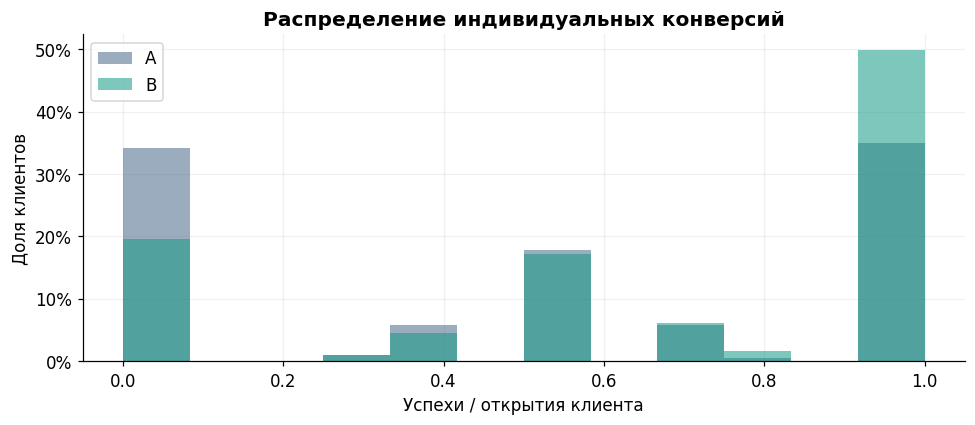

In [9]:
user_a = client.loc[client['group'].eq('A'), 'user_cr'].to_numpy()
user_b = client.loc[client['group'].eq('B'), 'user_cr'].to_numpy()
welch = stats.ttest_ind(user_b, user_a, equal_var=False, alternative='two-sided')
welch_ci = welch.confidence_interval(confidence_level=0.95)
mann = stats.mannwhitneyu(user_b, user_a, alternative='two-sided', method='asymptotic', use_continuity=True)
rank_probability = mann.statistic / (len(user_b) * len(user_a))
test_comparison = pd.DataFrame([
    {'Метод': 'Основной, клиентский delta', 'Что сравниваем': 'Отношения сумм',
     'statistic': main['statistic'], 'p_value': main['p_value']},
    {'Метод': 'Welch t-test', 'Что сравниваем': 'Средние клиентские CR',
     'statistic': welch.statistic, 'p_value': welch.pvalue},
    {'Метод': 'Манн — Уитни', 'Что сравниваем': 'Распределения клиентских CR',
     'statistic': mann.statistic, 'p_value': mann.pvalue},
])
display(test_comparison)
print(f'Средние клиентские CR: A {user_a.mean():.2%}, B {user_b.mean():.2%}.')
print(f'Welch, разница {100 * (user_b.mean() - user_a.mean()):+.2f} п.п.,')
print(f'95% ДИ [{100 * welch_ci.low:+.2f}, {100 * welch_ci.high:+.2f}] п.п., p={welch.pvalue:.3g}.')
print(f'Манн — Уитни U={mann.statistic:.1f}, p={mann.pvalue:.3g}.')
print(f'P(CR_B > CR_A) + 0.5 × P(равенство), эмпирическая оценка {rank_probability:.3f}.')

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 13)
ax.hist(user_a, bins=bins, weights=np.ones(len(user_a)) / len(user_a), alpha=0.55, label='A', color=COLORS['A'])
ax.hist(user_b, bins=bins, weights=np.ones(len(user_b)) / len(user_b), alpha=0.55, label='B', color=COLORS['B'])
ax.set(title='Распределение индивидуальных конверсий', xlabel='Успехи / открытия клиента', ylabel='Доля клиентов')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend()
fig.tight_layout()
fig.savefig(OUT / '05_user_conversion.png', bbox_inches='tight')
plt.show()

## 8. Проверки устойчивости и сегменты

Проверим результат на первой попытке, по доле клиентов с хотя бы одной оплатой,
на всех назначенных клиентах и при исключении попытки с конфликтом меток.
Различия после округления могут отличаться от вычитания уже округлённых процентов.

В сегментах считаем ту же ratio-метрику и клиентский дельта-интервал.
Срезы разведочные, интервалы представлены без поправки на множественные сравнения.
Положительные эффекты внутри сегментов сами по себе не доказывают различие эффектов
между сегментами. Для такого вывода нужна заранее выбранная проверка взаимодействия.

Без конфликтной попытки эффект +14.626 п.п.
ITT. Клиенты с оплатой / назначенные клиенты
Время рассчитано среди успешных попыток, состав которых может различаться между A и B.


group,A,B,difference_pp
Средняя клиентская конверсия,50.3000,65.5330,15.2340
Хотя бы одна оплата среди открывших,65.7790,80.4000,14.6210
Успех первой попытки,50.8660,65.7330,14.8680
"Хотя бы одна оплата среди назначенных, ITT",65.6910,80.2930,14.6010


,clients,paid
group,,
A,752,494
B,751,603


,segment,clients_a,clients_b,effect_pp,ci_low_pp,ci_high_pp
0,android,407,369,14.8600,9.7800,19.9400
1,ios,344,381,14.1200,8.7000,19.5500
2,Москва,288,306,18.1600,12.3600,23.9600
3,Санкт-Петербург,194,199,14.2400,7.1600,21.3200
4,Другие регионы,268,245,10.6900,4.1200,17.2600


,median_minutes,p90_minutes
group,,
A,12.0000,16.0000
B,12.0000,16.0000


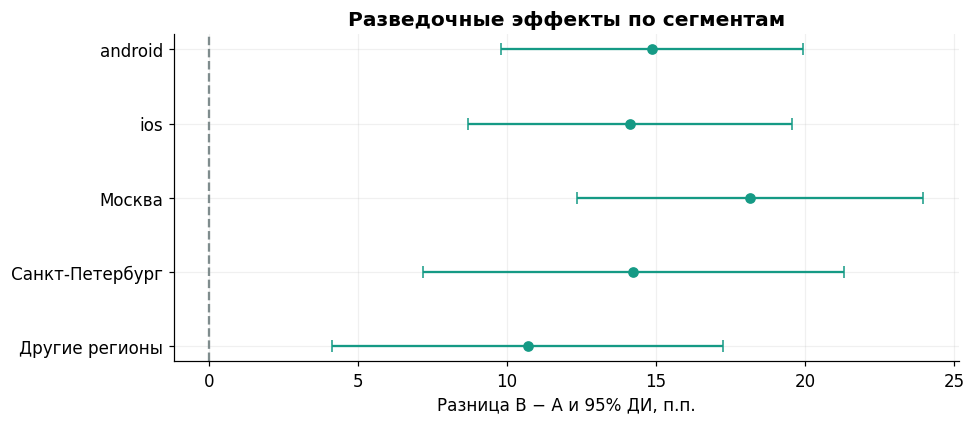

In [10]:
robustness = pd.DataFrame({
    'Средняя клиентская конверсия': client.groupby('group')['user_cr'].mean(),
    'Хотя бы одна оплата среди открывших': client.groupby('group')['any_success'].mean(),
    'Успех первой попытки': client.groupby('group')['first_success'].mean(),
    'Хотя бы одна оплата среди назначенных, ITT': assigned.groupby('group')['any_success'].mean(),
}).T
robustness['difference_pp'] = 100 * (robustness['B'] - robustness['A'])
robustness[['A', 'B']] *= 100
display(robustness.round(3))

without_conflict = events.loc[~events['label_conflict']].groupby(['user_id', 'group'], as_index=False).agg(
    opens=('success', 'size'), successes=('success', 'sum')
)
sensitivity = compare_ratios(without_conflict)
print(f"Без конфликтной попытки эффект {100 * sensitivity['difference']:+.3f} п.п.")
print('ITT. Клиенты с оплатой / назначенные клиенты')
display(assigned.groupby('group').agg(clients=('user_id', 'size'), paid=('any_success', 'sum')))

segment_rows = []
for column, levels in [('device_type', ['android', 'ios']),
                       ('city_clean', ['Москва', 'Санкт-Петербург', 'Другие регионы'])]:
    for level in levels:
        frame = client.loc[client[column].eq(level)]
        result = compare_ratios(frame)
        segment_rows.append({'segment': level, 'clients_a': int(frame['group'].eq('A').sum()),
            'clients_b': int(frame['group'].eq('B').sum()), 'effect_pp': 100 * result['difference'],
            'ci_low_pp': 100 * result['ci_low'], 'ci_high_pp': 100 * result['ci_high']})
segments = pd.DataFrame(segment_rows)
display(segments.round(2))

successful_times = events.loc[events['success'].eq(1)].groupby('group')['minutes_to_success'].quantile([0.5, 0.9]).unstack()
successful_times.columns = ['median_minutes', 'p90_minutes']
display(successful_times)
print('Время рассчитано среди успешных попыток, состав которых может различаться между A и B.')

fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(segments))
ax.errorbar(segments['effect_pp'], positions,
    xerr=np.vstack([segments['effect_pp'] - segments['ci_low_pp'], segments['ci_high_pp'] - segments['effect_pp']]),
    fmt='o', color=COLORS['B'], capsize=4)
ax.axvline(0, color='#7f8c8d', linestyle='--')
ax.set_yticks(positions, labels=segments['segment'])
ax.invert_yaxis()
ax.set(title='Разведочные эффекты по сегментам', xlabel='Разница B − A и 95% ДИ, п.п.')
fig.tight_layout()
fig.savefig(OUT / '06_segments.png', bbox_inches='tight')
plt.show()

## 9. A/A-переразбиения на контрольной группе

Возьмём только клиентов исходной A, которые видели одну форму по назначению реестра.
Исключим клиента с конфликтной записью, так как фактический показ требует проверки.
Сначала поделим этих клиентов по соли на две учебные группы и применим основной метод.
Затем 1 000 раз случайно переразобьём тот же контрольный пул на две почти равные части.
Сохраняем все попытки клиента вместе.

Гистограмма p-value и доля результатов ниже 5% помогают оценить поведение процедуры
при искусственном нулевом воздействии. Показываем Monte Carlo интервал для этой доли.
Один случайный результат с p < 0,05 ожидаем с некоторой вероятностью даже при A/A.
Для проверки всей системы назначения, показа и логирования нужен отдельный реальный A/A-запуск.

Одно хэш-разбиение A/A, p=0.2988.
Значимых результатов 49 / 1000 = 4.9%.
Monte Carlo 95% интервал для доли срабатываний [3.7%, 6.4%].


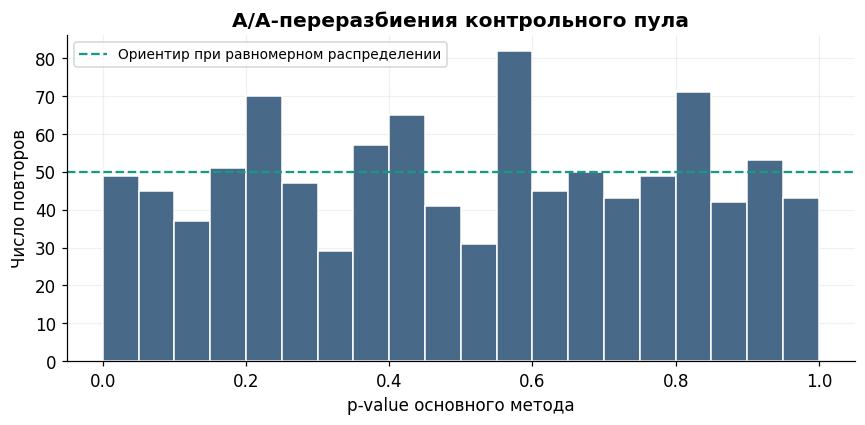

In [12]:
def stable_number(user_id, salt, experiment='housing_future_v1'):
    payload = f'{experiment}|{salt}|{int(user_id)}'.encode('utf-8')
    return int.from_bytes(sha256(payload).digest(), byteorder='big')
def assign_group(user_id, salt, experiment='housing_future_v1'):
    threshold = 1 << 255
    return 'A' if stable_number(user_id, salt, experiment) < threshold else 'B'


conflict_users = events.loc[events['label_conflict'], 'user_id']
aa_pool = client.loc[client['group'].eq('A') & ~client['user_id'].isin(conflict_users)].copy()
aa_hash = aa_pool.copy()
aa_hash['group'] = aa_hash['user_id'].map(lambda uid: assign_group(uid, 'aa-fixed-salt-v1'))
aa_single = compare_ratios(aa_hash)
print(f"Одно хэш-разбиение A/A, p={aa_single['p_value']:.4f}.")

aa_rng = np.random.default_rng(SEED + 2)
aa_values = aa_pool[['successes', 'opens']].to_numpy(dtype=float)
aa_pvalues = np.empty(1_000)


def ratio_variance_array(values):
    rate = values[:, 0].sum() / values[:, 1].sum()
    residuals = values[:, 0] - rate * values[:, 1]
    variance = residuals.var(ddof=1) / (len(values) * values[:, 1].mean() ** 2)
    return rate, variance


for repeat in range(len(aa_pvalues)):
    order = aa_rng.permutation(len(aa_values))
    midpoint = len(order) // 2
    ra, va = ratio_variance_array(aa_values[order[:midpoint]])
    rb, vb = ratio_variance_array(aa_values[order[midpoint:]])
    aa_pvalues[repeat] = 2 * stats.norm.sf(abs((rb - ra) / np.sqrt(va + vb)))
aa_rejections = int((aa_pvalues < ALPHA).sum())
aa_rate = aa_rejections / len(aa_pvalues)
aa_ci = proportion_confint(aa_rejections, len(aa_pvalues), alpha=ALPHA, method='wilson')
print(f'Значимых результатов {aa_rejections} / {len(aa_pvalues)} = {aa_rate:.1%}.')
print(f'Monte Carlo 95% интервал для доли срабатываний [{aa_ci[0]:.1%}, {aa_ci[1]:.1%}].')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(aa_pvalues, bins=np.linspace(0, 1, 21), color=COLORS['A'], edgecolor='white')
ax.axhline(len(aa_pvalues) / 20, color=COLORS['B'], linestyle='--', label='Ориентир при равномерном распределении')
ax.set(title='A/A-переразбиения контрольного пула', xlabel='p-value основного метода', ylabel='Число повторов')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT / '07_aa.png', bbox_inches='tight')
plt.show()

## 10. Бакетное преобразование

В каждой экспериментальной группе объединяем клиентов в 30 бакетов по независимому хэшу
`user_id`. Для каждого бакета считаем сумму успехов / сумму открытий.
Затем сравниваем бакетные конверсии Welch t-test. Все попытки одного клиента остаются вместе.

Бакеты укрупняют единицу анализа. Итоговое среднее даёт бакетам равный вес, поэтому при
разном размере бакетов его точечная оценка может отличаться от общей конверсии.
Это дополнительная приблизительная проверка. Основная оценка эффекта остаётся клиентским delta.
Для малой выборки число бакетов ограничено. В таблице покажем чувствительность к
заранее выбранным K = 20, 30 и 50, сохраняя одну соль для всех расчётов.

In [13]:
def make_buckets(frame, n_buckets):
    prepared = frame.copy()
    prepared['bucket'] = prepared['user_id'].map(
        lambda uid: stable_number(uid, 'independent-bucket-salt-v1') % n_buckets
    )
    table = prepared.groupby(['group', 'bucket'], as_index=False).agg(
        clients=('user_id', 'size'), opens=('opens', 'sum'), successes=('successes', 'sum')
    )
    table['cr'] = table['successes'] / table['opens']
    return table


bucket_rows = []
for k in [20, 30, 50]:
    table = make_buckets(client, k)
    a = table.loc[table['group'].eq('A'), 'cr'].to_numpy()
    b = table.loc[table['group'].eq('B'), 'cr'].to_numpy()
    result = stats.ttest_ind(b, a, equal_var=False)
    interval = result.confidence_interval()
    bucket_rows.append({'K': k, 'buckets_a': len(a), 'buckets_b': len(b),
        'minimum_clients_per_bucket': table['clients'].min(),
        'effect_pp': 100 * (b.mean() - a.mean()), 'ci_low_pp': 100 * interval.low,
        'ci_high_pp': 100 * interval.high, 'p_value': result.pvalue})
bucket_results = pd.DataFrame(bucket_rows)
buckets = make_buckets(client, 30)
assert buckets['clients'].sum() == len(client)
assert buckets['opens'].sum() == len(events)
assert buckets['successes'].sum() == events['success'].sum()
display(bucket_results)
display(buckets.head(6))

,K,buckets_a,buckets_b,minimum_clients_per_bucket,effect_pp,ci_low_pp,ci_high_pp,p_value
0,20,20,20,25,14.6206,11.2581,17.9830,0.0000
1,30,30,30,12,14.6523,11.1697,18.1349,0.0000
2,50,50,50,6,14.7894,10.7222,18.8566,0.0000


,group,bucket,clients,opens,successes,cr
0,A,0,23,48,23,0.4792
1,A,1,28,48,26,0.5417
2,A,2,23,42,21,0.5000
3,A,3,27,41,19,0.4634
4,A,4,23,50,22,0.4400
5,A,5,25,41,18,0.4390


## 11. Рекомендация продуктовой команде

**Внедрять вариант B поэтапно.** Прирост общей конверсии статистически значим и согласуется с результатами проверок на уровне клиента.

Среди успешных попыток медиана времени от открытия до оплаты - 12 минут, 90-й перцентиль - 16 минут в обеих группах. Для оценки финансового эффекта нужны суммы платежей и расходы.